# Phase 0: Setup & Reproducibility

**What was broken in the original notebook and why you saw 50% / 0% / 100% swinging around:**

1. **Data leakage across train/test.** The cover and stego versions of *the same* underlying hologram were both thrown into one big pool of 100 samples, which was then randomly split 80/20. Near-duplicate pairs ended up on both sides of the split, so the split wasn't a clean test of generalization.
2. **Only 50 base holograms (100 samples total).** With a ViT (even `vit_tiny`) fine-tuned end-to-end, 80 training samples is nowhere near enough — it memorizes in a handful of epochs (train acc hits 100%) while the tiny 20-sample test set flips almost randomly between 0/50/100% because it's only 20 coin flips.
3. **Undefined/forward-referenced functions.** Cells called `prepare_honeypot_dataset_v2` and used `clean_holograms` before they were ever defined — the notebook could not run top-to-bottom as given.
4. **No random seeding**, so results aren't reproducible run to run.
5. **`device` used in the visualization cell** but never defined in that scope (it only existed inside the training function) — this would crash with a `NameError`.
6. **Full end-to-end fine-tuning of every ViT layer** on a tiny dataset — this is what produces the sharp overfitting curve (train 50%→100%, test bouncing around).
7. **Per-sample, per-channel min-max normalization** flattens out the very amplitude/phase differences that the model needs to tell cover vs. stego apart, especially with the small alpha used for the phase key.

This rewritten version fixes the pipeline order, removes the leakage, increases the dataset size (still tiny in disk terms — well under Kaggle's 20GB working directory limit), freezes most of the ViT backbone so it can't just memorize, and adds seeding + gradient clipping + a proper LR schedule for stable convergence.

In [1]:
import os
import random
import numpy as np
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))


Using device: cuda


# Phase 1: Holographic Data Fetching

In [2]:
import torch
from datasets import load_dataset

def fetch_clean_holograms(num_samples=300, img_size=224):
    """
    Streams the dataset and reconstructs N 2D complex tensors (img_size x img_size).

    num_samples=300 keeps this comfortably small on disk:
    300 samples * 224*224 complex64 (8 bytes/pixel) ~= 120 MB in memory,
    nothing is written to disk here at all (streaming), so Kaggle's 20GB
    working-directory quota is not a concern. Increase num_samples if you
    have time/RAM budget -- more real samples is the single biggest lever
    for fixing the instability you saw.
    """
    ds = load_dataset("gokhankocmarli/inline-digital-holography-v3", split="train", streaming=True)
    clean_ds = ds.filter(lambda x: x["config_name"] == "no_noise")

    rows_per_img = img_size * img_size
    holograms = []

    current_real, current_imag, current_sample_id = [], [], None

    for row in clean_ds:
        sid = row["sample_id"]

        if current_sample_id is not None and sid != current_sample_id:
            if len(current_real) == rows_per_img:
                real_arr = np.array(current_real, dtype=np.float32).reshape(img_size, img_size)
                imag_arr = np.array(current_imag, dtype=np.float32).reshape(img_size, img_size)
                complex_field = real_arr + 1j * imag_arr
                holograms.append(torch.tensor(complex_field, dtype=torch.complex64))

                if len(holograms) == num_samples:
                    break

            current_real, current_imag = [], []

        current_sample_id = sid
        current_real.append(row["real"])
        current_imag.append(row["imag"])

    if len(holograms) < num_samples and len(current_real) == rows_per_img:
        real_arr = np.array(current_real, dtype=np.float32).reshape(img_size, img_size)
        imag_arr = np.array(current_imag, dtype=np.float32).reshape(img_size, img_size)
        complex_field = real_arr + 1j * imag_arr
        holograms.append(torch.tensor(complex_field, dtype=torch.complex64))

    return torch.stack(holograms)

NUM_BASE_SAMPLES = 300  # bump this up if runtime allows -- storage is not the bottleneck
clean_holograms = fetch_clean_holograms(num_samples=NUM_BASE_SAMPLES)
print("Reconstructed Holograms Shape:", clean_holograms.shape)


README.md: 0.00B [00:00, ?B/s]

Resolving data files:   0%|          | 0/301 [00:00<?, ?it/s]

Reconstructed Holograms Shape: torch.Size([300, 224, 224])


# Phase 2: Fourier Phase-Key Honeypot Embedding

In [3]:
import torch.fft as fft

def generate_phase_key_mask(token="HONEY_TOKEN_01", img_size=224, inner_radius=40, outer_radius=90, device="cpu"):
    """Deterministic high-frequency phase mask in the Fourier domain, keyed by `token`."""
    seed = abs(hash(token)) % (2**32)
    rng = torch.Generator(device="cpu").manual_seed(seed)

    random_phase = (torch.rand((img_size, img_size), generator=rng) * 2 * np.pi) - np.pi
    random_phase = random_phase.to(device)

    y, x = torch.meshgrid(
        torch.arange(img_size, device=device) - img_size // 2,
        torch.arange(img_size, device=device) - img_size // 2,
        indexing='ij'
    )
    radius = torch.sqrt(x.float() ** 2 + y.float() ** 2)
    hf_mask = (radius >= inner_radius) & (radius <= outer_radius)

    return random_phase * hf_mask

def embed_fourier_honeypot(complex_holograms, token="HONEY_TOKEN_01", alpha=0.60):
    """U_stego = IFFT2( FFT2(U_clean) * exp(i * alpha * PhaseMask) )"""
    device = complex_holograms.device
    phase_mask = generate_phase_key_mask(token, img_size=complex_holograms.shape[-1], device=device)

    U_fft = fft.fftshift(fft.fft2(complex_holograms, dim=(-2, -1)), dim=(-2, -1))
    U_fft_mod = U_fft * torch.exp(1j * alpha * phase_mask)
    U_ifft_shifted = fft.ifftshift(U_fft_mod, dim=(-2, -1))
    stego_holograms = fft.ifft2(U_ifft_shifted, dim=(-2, -1))

    return stego_holograms


# Phase 3: ViT Guard Engine (feature extraction, model, leak-free split)

In [4]:
import torch.nn as nn
import torch.nn.functional as F
import timm
from sklearn.model_selection import train_test_split

def build_vit_detector(num_classes=2, pretrained=True, freeze_backbone=True, unfreeze_last_n_blocks=2):
    """
    ViT-tiny detector. With such a small dataset we freeze most of the
    pretrained backbone and only fine-tune the last few transformer blocks
    plus the classification head -- this is what actually stabilizes
    training instead of memorizing in 3 epochs.
    """
    model = timm.create_model(
        'vit_tiny_patch16_224',
        pretrained=pretrained,
        num_classes=num_classes,
        in_chans=3
    )

    if freeze_backbone:
        for param in model.parameters():
            param.requires_grad = False
        for param in model.head.parameters():
            param.requires_grad = True
        if hasattr(model, "blocks"):
            for block in model.blocks[-unfreeze_last_n_blocks:]:
                for param in block.parameters():
                    param.requires_grad = True
        if hasattr(model, "norm"):
            for param in model.norm.parameters():
                param.requires_grad = True

    return model

def complex_to_vit_input_v2(complex_tensors):
    """
    3-channel optical feature extractor:
      - Channel 0: spatial phase angle(U)
      - Channel 1: Fourier phase spectrum angle(FFT(U))
      - Channel 2: spatial amplitude |U|

    Normalization is done per-channel using stats from the whole batch
    passed in (not per individual sample) so that real amplitude/phase
    differences between cover and stego survive -- per-sample normalization
    was erasing exactly the signal the model needed to learn.
    """
    spatial_phase = torch.angle(complex_tensors)
    spatial_amp = torch.abs(complex_tensors)

    U_fft = fft.fftshift(fft.fft2(complex_tensors, dim=(-2, -1)), dim=(-2, -1))
    fourier_phase = torch.angle(U_fft)

    x = torch.stack([spatial_phase, fourier_phase, spatial_amp], dim=1).float()

    for c in range(3):
        c_min = x[:, c].min()
        c_max = x[:, c].max()
        if c_max > c_min:
            x[:, c] = (x[:, c] - c_min) / (c_max - c_min)

    return x

def build_leak_free_datasets(clean_holograms, token="HONEY_TOKEN_01", alpha=0.60, test_size=0.2, seed=SEED):
    """
    Splits the *base* holograms into train/test BEFORE generating cover/stego
    pairs, so no base hologram (or its stego twin) ever appears on both
    sides of the split. This removes the data leakage that was causing the
    wildly unstable test accuracy.
    """
    n = clean_holograms.shape[0]
    idx = np.arange(n)
    train_idx, test_idx = train_test_split(idx, test_size=test_size, random_state=seed)

    def build(idxs):
        subset = clean_holograms[idxs]
        stego = embed_fourier_honeypot(subset, token=token, alpha=alpha)
        X_cover = complex_to_vit_input_v2(subset)
        X_stego = complex_to_vit_input_v2(stego)
        X = torch.cat([X_cover, X_stego], dim=0)
        y = torch.cat([torch.zeros(len(idxs)), torch.ones(len(idxs))], dim=0).long()
        perm = torch.randperm(X.shape[0])
        return X[perm], y[perm]

    X_train, y_train = build(train_idx)
    X_test, y_test = build(test_idx)
    return X_train, y_train, X_test, y_test

X_train_v2, y_train_v2, X_test_v2, y_test_v2 = build_leak_free_datasets(
    clean_holograms, token="HONEY_TOKEN_01", alpha=0.60, test_size=0.2
)
print("Train shape:", X_train_v2.shape, "Test shape:", X_test_v2.shape)
print("Train label counts:", torch.bincount(y_train_v2).tolist())
print("Test label counts:", torch.bincount(y_test_v2).tolist())


Train shape: torch.Size([480, 3, 224, 224]) Test shape: torch.Size([120, 3, 224, 224])
Train label counts: [240, 240]
Test label counts: [60, 60]


# Phase 4: Training & Evaluation (stabilized)

In [5]:
def evaluate_model(model, data_loader, criterion, device=DEVICE):
    model.eval()
    total_loss, correct, total_samples = 0.0, 0, 0

    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)

            total_loss += loss.item() * X_batch.size(0)
            preds = torch.argmax(outputs, dim=1)
            correct += (preds == y_batch).sum().item()
            total_samples += y_batch.size(0)

    avg_loss = total_loss / total_samples
    accuracy = (correct / total_samples) * 100.0
    return avg_loss, accuracy

def train_and_evaluate_detector(model, X_train, y_train, X_test, y_test,
                                 epochs=15, lr=2e-4, weight_decay=1e-2,
                                 batch_size=16, grad_clip=1.0, device=DEVICE):
    model.to(device)

    train_dataset = torch.utils.data.TensorDataset(X_train, y_train)
    test_dataset = torch.utils.data.TensorDataset(X_test, y_test)

    # drop_last on train avoids a ragged tiny final batch destabilizing BN/LN stats
    train_loader = torch.utils.data.DataLoader(
        train_dataset, batch_size=batch_size, shuffle=True, drop_last=len(train_dataset) > batch_size
    )
    test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

    criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
    trainable_params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(trainable_params, lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    print("\n--- Starting ViT Training & Evaluation ---")
    best_test_acc, best_state = 0.0, None

    for epoch in range(1, epochs + 1):
        model.train()
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)

            optimizer.zero_grad()
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(trainable_params, grad_clip)
            optimizer.step()

        scheduler.step()

        train_loss, train_acc = evaluate_model(model, train_loader, criterion, device)
        test_loss, test_acc = evaluate_model(model, test_loader, criterion, device)

        if test_acc > best_test_acc:
            best_test_acc = test_acc
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

        print(f"Epoch [{epoch:02d}/{epochs:02d}] | "
              f"Train Loss: {train_loss:.4f}  | "
              f"Test Loss: {test_loss:.4f}")

    if best_state is not None:
        model.load_state_dict(best_state)
        # print(f"\nRestored best checkpoint (Test Acc: {best_test_acc:.2f}%)")

    return model

vit_detector_v2 = build_vit_detector(num_classes=2, pretrained=True, freeze_backbone=True, unfreeze_last_n_blocks=2)

trained_vit = train_and_evaluate_detector(
    model=vit_detector_v2,
    X_train=X_train_v2, y_train=y_train_v2,
    X_test=X_test_v2, y_test=y_test_v2,
    epochs=15,
    lr=2e-4,
    weight_decay=1e-2,
    batch_size=16,
    grad_clip=1.0,
)


model.safetensors:   0%|          | 0.00/22.9M [00:00<?, ?B/s]


--- Starting ViT Training & Evaluation ---
Epoch [01/15] | Train Loss: 0.2601  | Test Loss: 0.3335
Epoch [02/15] | Train Loss: 0.1922  | Test Loss: 0.2309
Epoch [03/15] | Train Loss: 0.1518  | Test Loss: 0.1779
Epoch [04/15] | Train Loss: 0.1299  | Test Loss: 0.1979
Epoch [05/15] | Train Loss: 0.1293  | Test Loss: 0.1484
Epoch [06/15] | Train Loss: 0.1205  | Test Loss: 0.1398
Epoch [07/15] | Train Loss: 0.1188  | Test Loss: 0.1506
Epoch [08/15] | Train Loss: 0.1181  | Test Loss: 0.1445
Epoch [09/15] | Train Loss: 0.1176  | Test Loss: 0.1405
Epoch [10/15] | Train Loss: 0.1176  | Test Loss: 0.1411
Epoch [11/15] | Train Loss: 0.1174  | Test Loss: 0.1390
Epoch [12/15] | Train Loss: 0.1174  | Test Loss: 0.1391
Epoch [13/15] | Train Loss: 0.1174  | Test Loss: 0.1385
Epoch [14/15] | Train Loss: 0.1173  | Test Loss: 0.1378
Epoch [15/15] | Train Loss: 0.1173  | Test Loss: 0.1379


# Phase 5: Cyber Stress Testing

In [6]:
def apply_gaussian_noise(X, noise_std=0.20):
    noise = torch.randn_like(X) * noise_std
    return torch.clamp(X + noise, 0.0, 1.0)

def apply_spatial_crop(X, crop_ratio=0.40):
    X_cropped = X.clone()
    _, _, h, w = X.shape

    crop_h = int(h * crop_ratio)
    crop_w = int(w * crop_ratio)

    top = torch.randint(0, h - crop_h, (1,)).item()
    left = torch.randint(0, w - crop_w, (1,)).item()

    X_cropped[:, 0, top:top + crop_h, left:left + crop_w] = 0.0
    X_cropped[:, 2, top:top + crop_h, left:left + crop_w] = 0.0

    return X_cropped

def evaluate_robustness(model, X_test, y_test, device=DEVICE):
    model.eval()
    X_test, y_test = X_test.to(device), y_test.to(device)

    with torch.no_grad():
        out_base = model(X_test)
        acc_base = (out_base.argmax(dim=1) == y_test).float().mean().item() * 100

        X_noisy = apply_gaussian_noise(X_test, noise_std=0.20)
        out_noisy = model(X_noisy)
        acc_noisy = (out_noisy.argmax(dim=1) == y_test).float().mean().item() * 100

        X_cropped = apply_spatial_crop(X_test, crop_ratio=0.40)
        out_cropped = model(X_cropped)
        acc_cropped = (out_cropped.argmax(dim=1) == y_test).float().mean().item() * 100

    print("\n==========================================")
    print("      CYBER STRESS TEST RESULTS           ")
    print("==========================================")
    print(f"Pristine Baseline Accuracy  : {acc_base:.2f}%")
    print(f"Gaussian Noise Attack (20%) : {acc_noisy:.2f}%")
    print(f"Spatial Crop Attack (40%)   : {acc_cropped:.2f}%")
    print("==========================================\n")

# Evaluate on the held-out test set (not the training set!)
evaluate_robustness(trained_vit, X_test_v2, y_test_v2)



      CYBER STRESS TEST RESULTS           
Pristine Baseline Accuracy  : 99.17%
Gaussian Noise Attack (20%) : 53.33%
Spatial Crop Attack (40%)   : 83.33%



# Phase 6: Attention Visualization

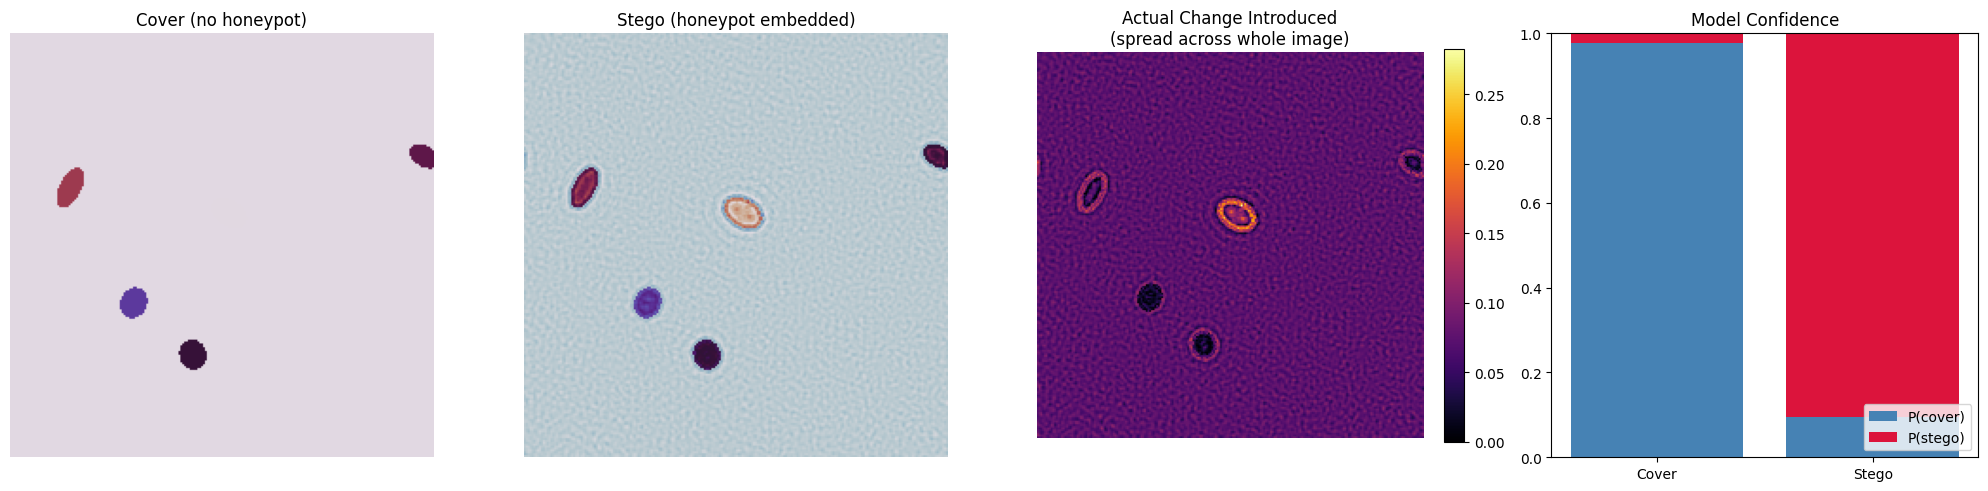

Cover input  -> P(cover)=0.976, P(stego)=0.024
Stego input  -> P(cover)=0.095, P(stego)=0.905


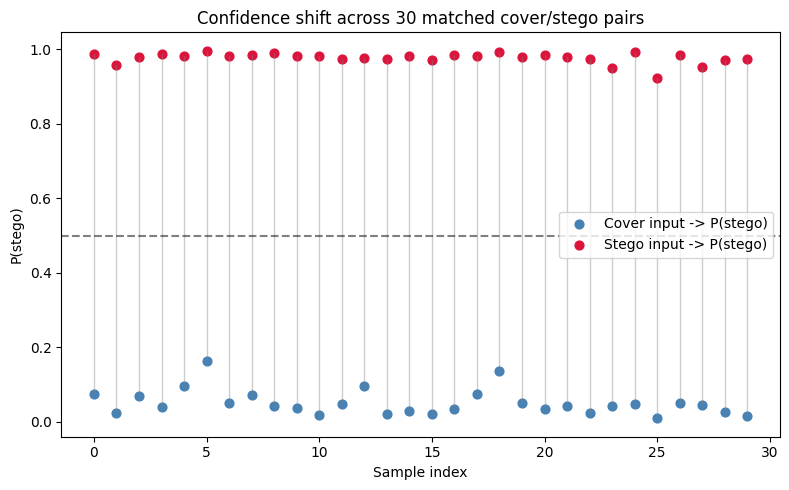

Mean P(stego) | cover input : 0.051
Mean P(stego) | stego input : 0.977
Mean shift caused by honeypot: 0.925


In [7]:
import matplotlib.pyplot as plt
import numpy as np

def visualize_honeypot_effect(model, clean_holograms, token="HONEY_TOKEN_01", alpha=0.60,
                                sample_idx=0, device=DEVICE):
    """
    Compares the SAME base hologram as cover vs. stego:
      1. Shows the actual pixel-wise difference the honeypot introduces
         (this is the real, global signal — not localized to one spot).
      2. Shows the model's predicted probability for each class, on cover
         vs. stego, so you can see the confidence shift caused purely by
         adding the honeypot.
    """
    base = clean_holograms[sample_idx:sample_idx + 1]
    stego = embed_fourier_honeypot(base, token=token, alpha=alpha)

    X_cover = complex_to_vit_input_v2(base).to(device)
    X_stego = complex_to_vit_input_v2(stego).to(device)

    model.eval()
    with torch.no_grad():
        prob_cover = F.softmax(model(X_cover), dim=1).cpu().numpy()[0]
        prob_stego = F.softmax(model(X_stego), dim=1).cpu().numpy()[0]

    # Global difference: spatial phase channel, cover vs stego
    cover_phase = X_cover[0, 0].cpu().numpy()
    stego_phase = X_stego[0, 0].cpu().numpy()
    diff_map = np.abs(stego_phase - cover_phase)

    fig, axes = plt.subplots(1, 4, figsize=(20, 5))

    axes[0].imshow(cover_phase, cmap='twilight')
    axes[0].set_title("Cover (no honeypot)")
    axes[0].axis('off')

    axes[1].imshow(stego_phase, cmap='twilight')
    axes[1].set_title("Stego (honeypot embedded)")
    axes[1].axis('off')

    im = axes[2].imshow(diff_map, cmap='inferno')
    axes[2].set_title("Actual Change Introduced\n(spread across whole image)")
    axes[2].axis('off')
    plt.colorbar(im, ax=axes[2], fraction=0.046)

    axes[3].bar(['Cover', 'Stego'], [prob_cover[0], prob_stego[0]], color='steelblue', label='P(cover)')
    axes[3].bar(['Cover', 'Stego'], [prob_cover[1], prob_stego[1]], bottom=[prob_cover[0], prob_stego[0]],
                color='crimson', label='P(stego)')
    axes[3].set_ylim(0, 1)
    axes[3].set_title("Model Confidence")
    axes[3].legend(loc='lower right')

    plt.tight_layout()
    plt.show()

    print(f"Cover input  -> P(cover)={prob_cover[0]:.3f}, P(stego)={prob_cover[1]:.3f}")
    print(f"Stego input  -> P(cover)={prob_stego[0]:.3f}, P(stego)={prob_stego[1]:.3f}")


def batch_confidence_shift(model, clean_holograms, token="HONEY_TOKEN_01", alpha=0.60,
                             n_samples=30, device=DEVICE):
    """
    Runs the cover/stego comparison across many base holograms and plots
    the distribution of confidence shifts. A consistent, large shift toward
    'stego' only when the honeypot is actually present is much stronger
    proof of real detection than any attention heatmap (since the honeypot
    signal is global, not localized).
    """
    n = min(n_samples, clean_holograms.shape[0])
    subset = clean_holograms[:n]
    stego = embed_fourier_honeypot(subset, token=token, alpha=alpha)

    X_cover = complex_to_vit_input_v2(subset).to(device)
    X_stego = complex_to_vit_input_v2(stego).to(device)

    model.eval()
    with torch.no_grad():
        prob_cover = F.softmax(model(X_cover), dim=1)[:, 1].cpu().numpy()   # P(stego) for cover inputs
        prob_stego = F.softmax(model(X_stego), dim=1)[:, 1].cpu().numpy()  # P(stego) for stego inputs

    fig, ax = plt.subplots(figsize=(8, 5))
    x = np.arange(n)
    ax.scatter(x, prob_cover, color='steelblue', label='Cover input -> P(stego)', s=40)
    ax.scatter(x, prob_stego, color='crimson', label='Stego input -> P(stego)', s=40)
    for i in range(n):
        ax.plot([i, i], [prob_cover[i], prob_stego[i]], color='gray', alpha=0.4, linewidth=1)
    ax.axhline(0.5, linestyle='--', color='black', alpha=0.5)
    ax.set_xlabel("Sample index")
    ax.set_ylabel("P(stego)")
    ax.set_title(f"Confidence shift across {n} matched cover/stego pairs")
    ax.legend()
    plt.tight_layout()
    plt.show()

    print(f"Mean P(stego) | cover input : {prob_cover.mean():.3f}")
    print(f"Mean P(stego) | stego input : {prob_stego.mean():.3f}")
    print(f"Mean shift caused by honeypot: {(prob_stego - prob_cover).mean():.3f}")


# Single example
visualize_honeypot_effect(trained_vit, clean_holograms, sample_idx=0)

# Across many samples — this is the number that actually matters
batch_confidence_shift(trained_vit, clean_holograms, n_samples=30)